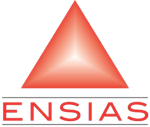

# TP 8 — DBSCAN

**Module :** Introduction au Machine Learning
**Enseignant :** Prof. Aissam BERRAHOU — ENSIAS, Université Mohammed V de Rabat
**Niveau :** 2e année cycle ingénieur
**Durée estimée :** 2 heures
**Support associé :** Lecture 8 — DBSCAN

## 1. Objectifs pédagogiques

*Ce TP prolonge le cours : vous allez refaire sur machine les calculs vus en séance, puis passer à un vrai jeu de données.*

1. Calculer les **ε-voisinages** et classer les points en **cœur, frontière, bruit** (exemple des slides).
2. Implémenter DBSCAN **sans scikit-learn**.
3. Vérifier avec `sklearn.cluster.DBSCAN`.
4. Choisir ε avec le **graphique des k-distances**.
5. Comparer DBSCAN et K-means sur des clusters non convexes.

## 2. Rappel théorique

*Avant de coder, un rapide rappel des formules dont nous aurons besoin.*

- **ε-voisinage :** $V_\varepsilon(x) = \{x' \in D \mid d(x, x') \le \varepsilon\}$ (x compris).
- **Point cœur :** $|V_\varepsilon(x)| \ge \text{MinPts}$.
- **Point frontière :** pas cœur, mais dans le voisinage d'un point cœur.
- **Bruit :** ni cœur, ni frontière.

Les points cœurs voisins forment un même cluster ; les points frontière rejoignent le cluster d'un cœur voisin.

## 3. Import des bibliothèques

*On charge d'abord les outils. Tout le TP n'utilise que NumPy, pandas, Matplotlib et scikit-learn.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons, make_blobs
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

## 4. Exemple jouet : 10 points, ε = 1, MinPts = 3

*Combien de groupes y a-t-il parmi ces dix points ? Laissons la densité répondre.*

In [2]:
X_points = np.array([[1, 1], [1.5, 1.2], [1.2, 1.8], [2, 1.5], [2.9, 1.6],
                     [6, 6], [6.4, 6.2], [6.2, 5.7], [5.5, 6.8], [8, 1]])
noms = list("ABCDEFGHIJ")
eps, min_pts = 1.0, 3
D = np.sqrt(((X_points[:, None, :] - X_points[None, :, :]) ** 2).sum(axis=2))   # distances
pd.DataFrame(D.round(2), index=noms, columns=noms)

,A,B,C,D,E,F,G,H,I,J
A,0.00,0.54,0.82,1.12,1.99,7.07,7.50,7.01,7.34,7.00
B,0.54,0.00,0.67,0.58,1.46,6.58,7.00,6.51,6.88,6.50
C,0.82,0.67,0.00,0.85,1.71,6.38,6.81,6.34,6.59,6.85
D,1.12,0.58,0.85,0.00,0.91,6.02,6.44,5.94,6.35,6.02
E,1.99,1.46,1.71,0.91,0.00,5.38,5.78,5.26,5.81,5.14
F,7.07,6.58,6.38,6.02,5.38,0.00,0.45,0.36,0.94,5.39
G,7.50,7.00,6.81,6.44,5.78,0.45,0.00,0.54,1.08,5.44
H,7.01,6.51,6.34,5.94,5.26,0.36,0.54,0.00,1.30,5.03
I,7.34,6.88,6.59,6.35,5.81,0.94,1.08,1.30,0.00,6.32
J,7.00,6.50,6.85,6.02,5.14,5.39,5.44,5.03,6.32,0.00


### 4.1 Étape 1 : ε-voisinages

*Qui sont les voisins de chaque point, à moins de ε ?*

In [3]:
voisinages = [np.where(D[i] <= eps)[0] for i in range(len(X_points))]     # x compris
taille = np.array([len(v) for v in voisinages])
pd.DataFrame({"voisins": [", ".join(noms[j] for j in v if j != i) for i, v in enumerate(voisinages)],
              "|V_eps|": taille}, index=noms)

,voisins,|V_eps|
A,"B, C",3
B,"A, C, D",4
C,"A, B, D",4
D,"B, C, E",4
E,D,2
F,"G, H, I",4
G,"F, H",3
H,"F, G",3
I,F,2
J,,1


### 4.2 Étape 2 : cœur, frontière, bruit

*Cœur, frontière ou bruit : quel rôle pour chaque point ?*

In [4]:
coeur = taille >= min_pts
types = []
for i in range(len(X_points)):
    if coeur[i]:
        types.append("cœur")
    elif any(coeur[j] for j in voisinages[i]):       # voisin d'un point cœur
        types.append("frontière")
    else:
        types.append("bruit")
pd.Series(types, index=noms, name="type")

A         cœur
B         cœur
C         cœur
D         cœur
E    frontière
F         cœur
G         cœur
H         cœur
I    frontière
J        bruit
Name: type, dtype: str

### 4.3 Étape 3 : DBSCAN « from scratch »

*Écrivons maintenant l'algorithme complet, sans scikit-learn.*

On propage chaque cluster à partir d'un point cœur, avec une liste de points à visiter :

In [5]:
def dbscan_scratch(X, eps, min_pts):
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
    etiquettes, visite = np.full(len(X), -1), np.zeros(len(X), dtype=bool)   # -1 = bruit (provisoire)
    cluster = -1
    for i in range(len(X)):
        if visite[i]:
            continue
        visite[i] = True
        voisins = list(np.where(D[i] <= eps)[0])
        if len(voisins) < min_pts:
            continue                                 # pas dense : reste bruit pour l'instant
        cluster += 1
        etiquettes[i] = cluster
        etendre_cluster(D, voisins, etiquettes, visite, cluster, eps, min_pts)
    return etiquettes

In [6]:
def etendre_cluster(D, a_visiter, etiquettes, visite, cluster, eps, min_pts):
    """Ajoute au cluster tous les points atteignables par densité."""
    while a_visiter:
        j = a_visiter.pop()
        if etiquettes[j] == -1:
            etiquettes[j] = cluster                  # cœur ou frontière rejoint le cluster
        if not visite[j]:
            visite[j] = True
            voisins_j = list(np.where(D[j] <= eps)[0])
            if len(voisins_j) >= min_pts:            # j est un cœur : on continue depuis lui
                a_visiter.extend(voisins_j)

In [7]:
etiquettes_scratch = dbscan_scratch(X_points, eps, min_pts)
print({n: int(e) for n, e in zip(noms, etiquettes_scratch)})

{'A': 0, 'B': 0, 'C': 0, 'D': 0, 'E': 0, 'F': 1, 'G': 1, 'H': 1, 'I': 1, 'J': -1}


✅ Deux clusters ({A, B, C, D, E} et {F, G, H, I}) et un point de bruit (J), comme dans les slides.

### 4.4 Vérification avec scikit-learn

*scikit-learn trouve-t-il les mêmes groupes ?*

In [8]:
modele = DBSCAN(eps=1.0, min_samples=3).fit(X_points)
print("étiquettes :", modele.labels_)                       # -1 = bruit
print("points cœurs :", [noms[i] for i in modele.core_sample_indices_])

étiquettes : [ 0  0  0  0  0  1  1  1  1 -1]
points cœurs : ['A', 'B', 'C', 'D', 'F', 'G', 'H']


### 4.5 Visualisation

*Une image pour voir les trois rôles d'un coup d'œil.*

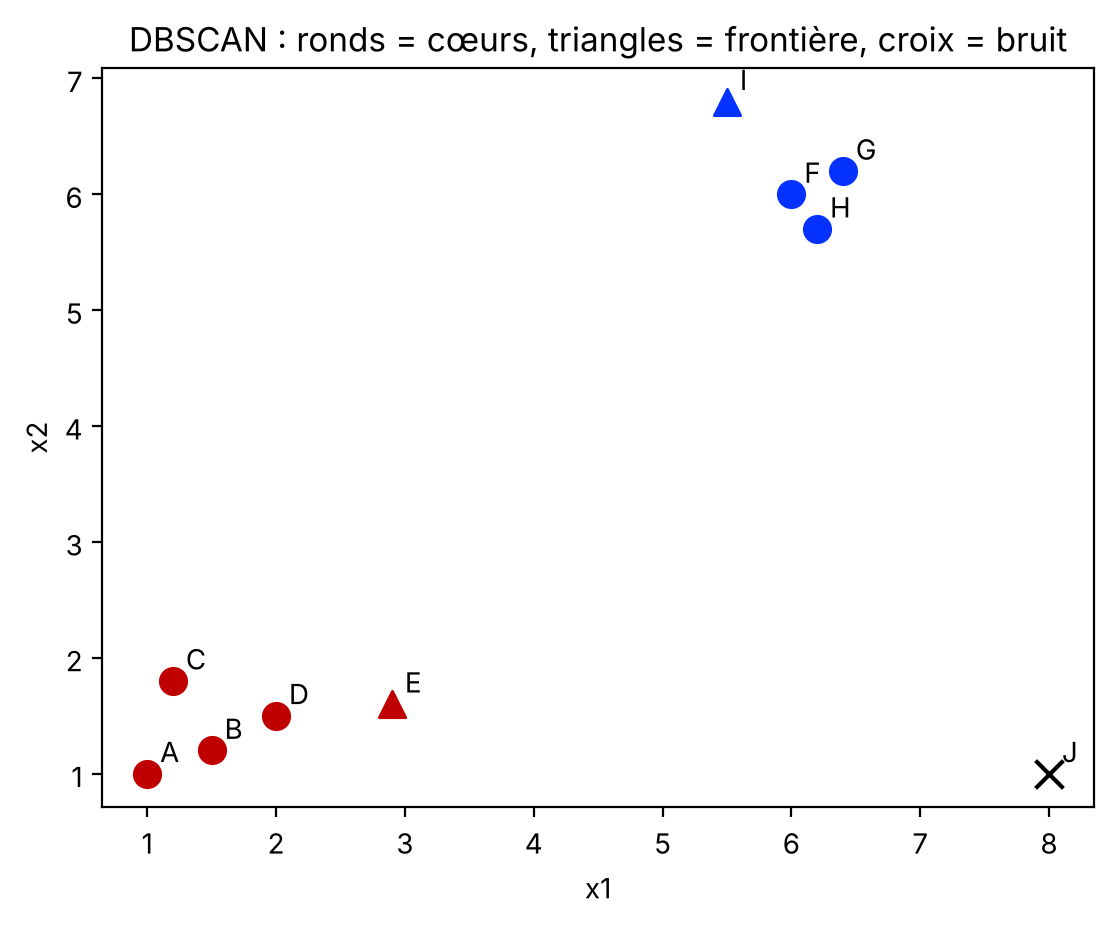

In [9]:
couleurs = np.array(["#C00000", "#0532FF"])
for i, (x, y) in enumerate(X_points):
    lab = modele.labels_[i]
    style = dict(c="black", marker="x", s=100) if lab == -1 else \
            dict(c=couleurs[lab], marker="o" if coeur[i] else "^", s=90)
    plt.scatter(x, y, **style); plt.annotate(noms[i], (x + 0.1, y + 0.1))
plt.title("DBSCAN : ronds = cœurs, triangles = frontière, croix = bruit")
plt.xlabel("x1"); plt.ylabel("x2"); plt.show()

## 5. Choisir ε : le graphique des k-distances

*Comment régler ε sans tâtonner ?*

Pour MinPts = 3, on regarde la distance de chaque point à son 2e plus proche voisin (le point lui-même étant le « 0e »).

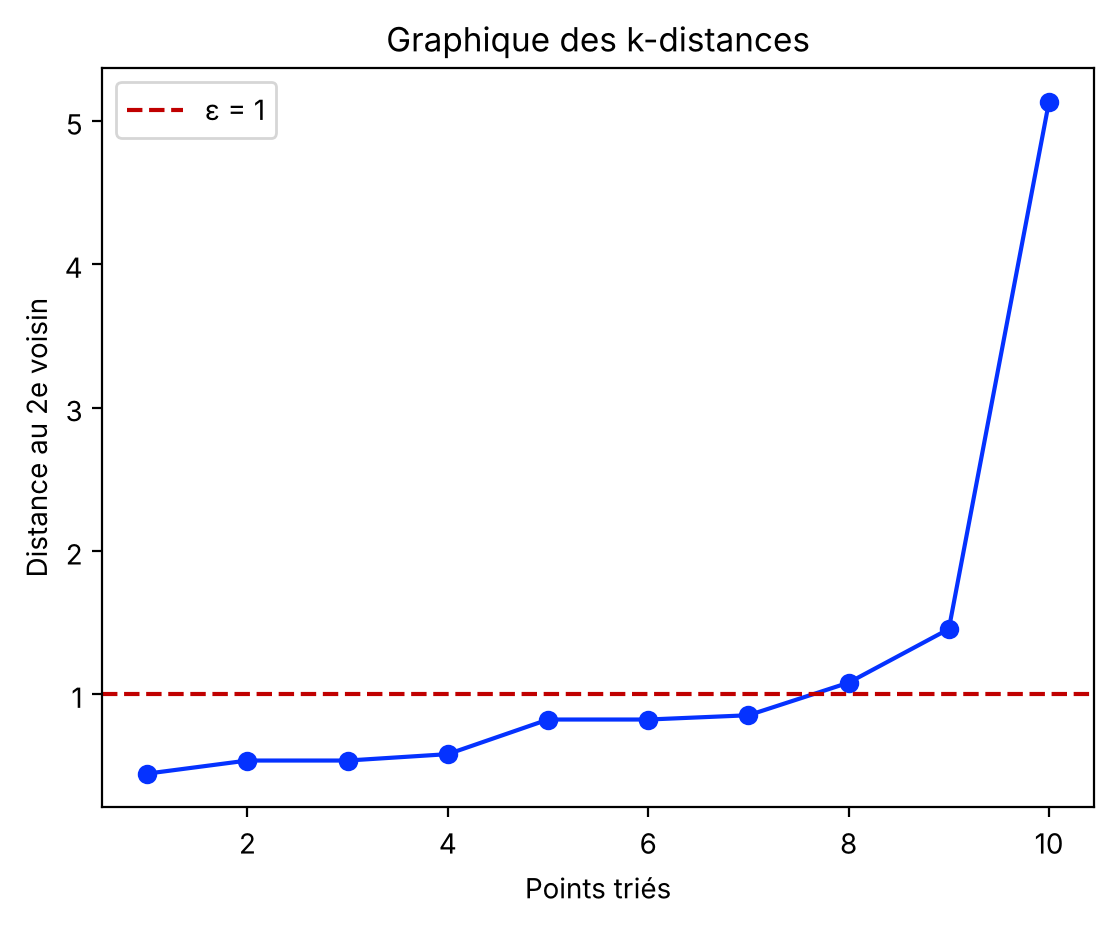

In [10]:
voisins = NearestNeighbors(n_neighbors=min_pts).fit(X_points)
distances, _ = voisins.kneighbors(X_points)          # colonne 0 = le point lui-même
k_dist = np.sort(distances[:, -1])
plt.plot(range(1, len(k_dist) + 1), k_dist, "o-", color="#0532FF")
plt.axhline(1.0, color="#C00000", ls="--", label="ε = 1")
plt.xlabel("Points triés"); plt.ylabel("Distance au 2e voisin"); plt.legend()
plt.title("Graphique des k-distances"); plt.show()

## 6. Cas pratique : clusters non convexes (`make_moons`)

*Là où K-means échoue, DBSCAN réussit-il ?*

In [11]:
X_lunes, y_lunes = make_moons(n_samples=400, noise=0.07, random_state=42)
X_lunes = StandardScaler().fit_transform(X_lunes)
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_lunes)
db = DBSCAN(eps=0.3, min_samples=5).fit_predict(X_lunes)
print("ARI K-means :", round(adjusted_rand_score(y_lunes, km), 3))
print("ARI DBSCAN  :", round(adjusted_rand_score(y_lunes, db), 3), "  points de bruit :", np.sum(db == -1))

ARI K-means : 0.475
ARI DBSCAN  : 0.995   points de bruit : 1


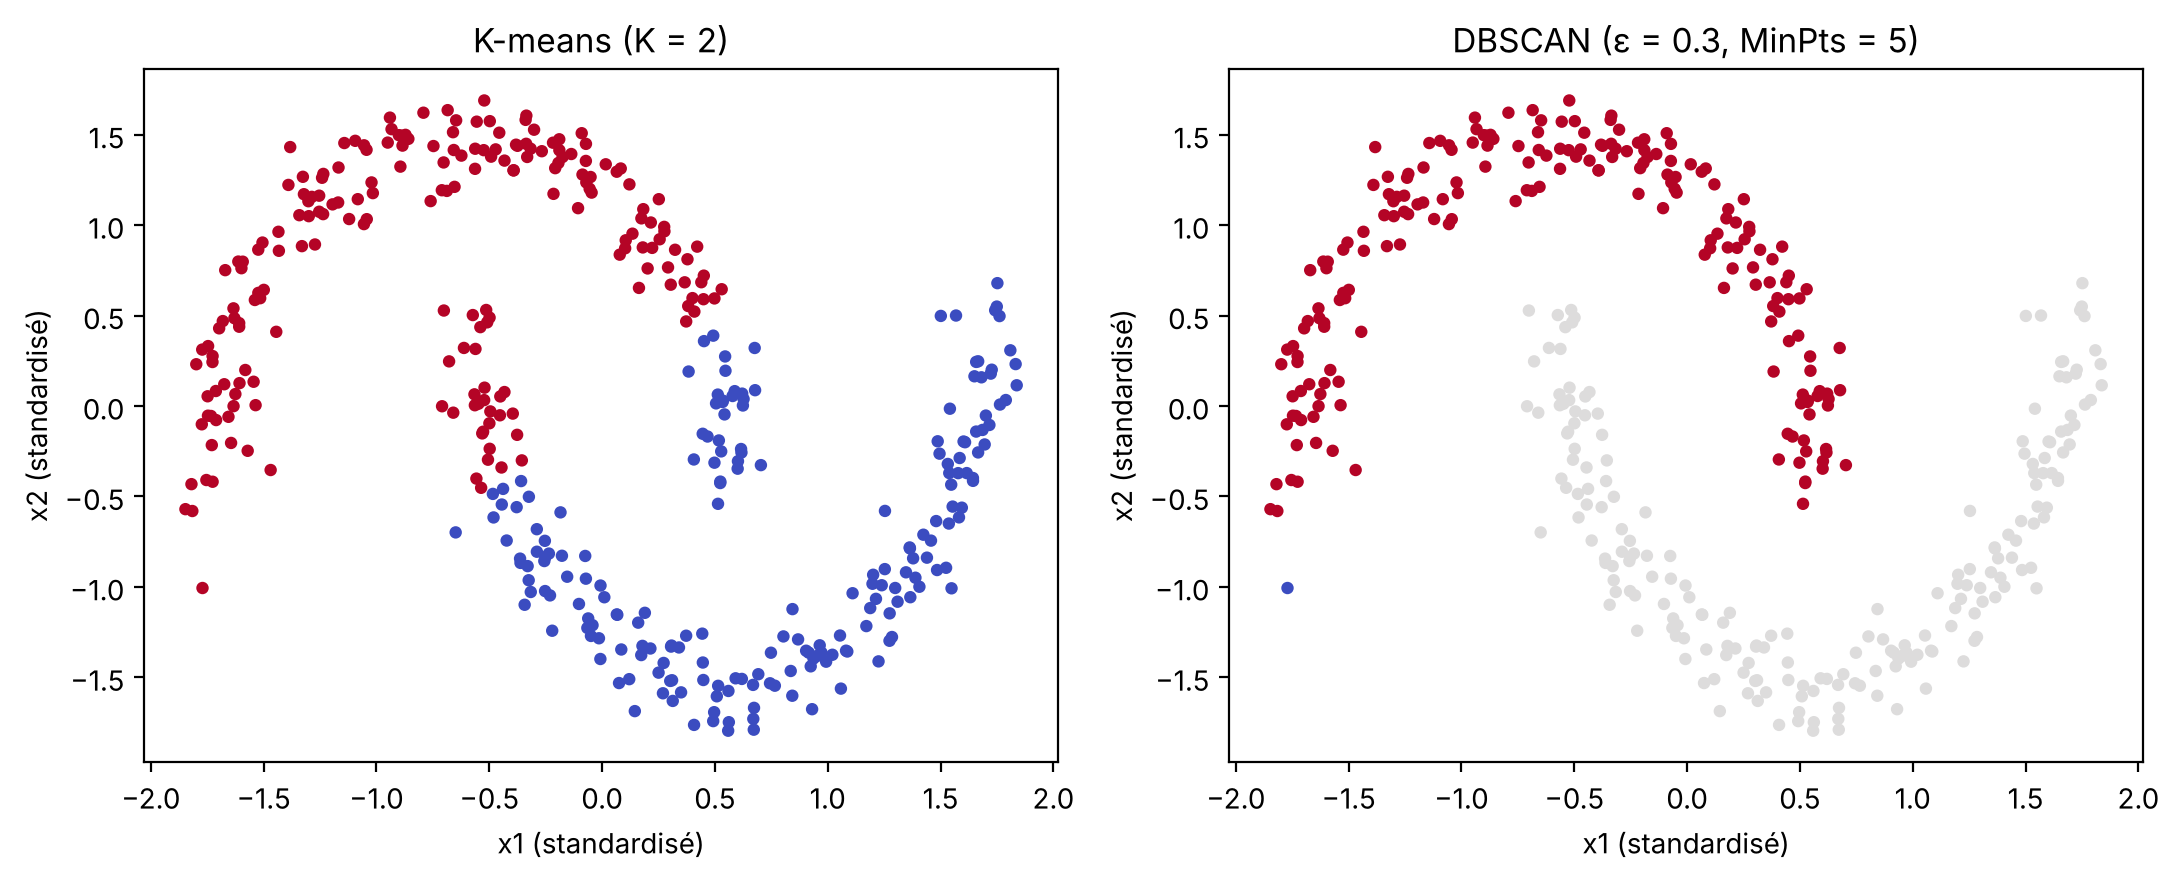

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(*X_lunes.T, c=km, cmap="coolwarm", s=12); axes[0].set_title("K-means (K = 2)")
axes[1].scatter(*X_lunes.T, c=db, cmap="coolwarm", s=12); axes[1].set_title("DBSCAN (ε = 0.3, MinPts = 5)")
for ax in axes:
    ax.set_xlabel("x1 (standardisé)"); ax.set_ylabel("x2 (standardisé)")
plt.tight_layout(); plt.show()

K-means coupe les lunes en deux moitiés ; DBSCAN suit leur forme.

## 7. Influence des hyperparamètres ε et MinPts

*Que se passe-t-il quand ε ou MinPts sont mal choisis ?*

In [13]:
resultats = []
for eps_test in [0.1, 0.2, 0.3, 0.5, 1.0]:
    for mp in [3, 5, 10]:
        lab = DBSCAN(eps=eps_test, min_samples=mp).fit_predict(X_lunes)
        resultats.append({"ε": eps_test, "MinPts": mp, "clusters": len(set(lab) - {-1}),
                          "bruit": int(np.sum(lab == -1)), "ARI": round(adjusted_rand_score(y_lunes, lab), 3)})
pd.DataFrame(resultats).pivot(index="ε", columns="MinPts", values="clusters")

MinPts,3,5,10
ε,,,
0.1,31,27,1
0.2,3,3,5
0.3,2,2,2
0.5,2,2,2
1.0,1,1,1


In [14]:
pd.DataFrame(resultats).pivot(index="ε", columns="MinPts", values="ARI")

MinPts,3,5,10
ε,,,
0.1,0.079,0.045,0.002
0.2,0.947,0.942,0.511
0.3,0.995,0.995,0.985
0.5,1.000,1.000,1.000
1.0,0.000,0.000,0.000


- ε trop petit : beaucoup de clusters minuscules et de bruit ;
- ε trop grand : tout fusionne en un seul cluster ;
- MinPts plus grand : il faut des zones plus denses pour former un cluster.

## 8. Exercices

*À vous de jouer ! Les exercices sont classés du plus simple au plus exigeant. Essayez de les faire sans regarder les solutions.*

### Exercice 1 (facile) — Changer MinPts
Sur les 10 points, relancez `dbscan_scratch` avec MinPts = 4 puis 2 (ε = 1). Quels points changent de type ?

In [15]:
# À compléter

### Exercice 2 (moyen) — Densités différentes
Générez `make_blobs(n_samples=[300, 100], centers=[[0, 0], [4, 4]], cluster_std=[0.3, 1.2], random_state=42)`. Essayez plusieurs ε. Pourquoi un seul ε ne convient-il pas aux deux groupes ?

In [16]:
# À compléter

### Exercice 3 (défi) — Choisir ε automatiquement
Sur `X_lunes`, tracez le graphique des k-distances pour MinPts = 5 et proposez une règle pour repérer le coude (par exemple le point le plus éloigné de la droite joignant le premier et le dernier point). Comparez l'ARI obtenu avec ε = 0.3.

In [17]:
# À compléter

## 9. Solutions

*Comparez vos réponses avec les propositions ci-dessous ; il existe souvent plusieurs façons correctes de faire.*

<details>
<summary><b>Solution de l'exercice 1</b> (cliquer pour afficher)</summary>

```python
for mp in [2, 3, 4]:
    print(mp, dict(zip(noms, dbscan_scratch(X_points, 1.0, mp))))
```
Avec MinPts = 4, seuls B, C, D et F restent des cœurs ; A, E, G, H et I deviennent des points frontière ; les clusters ne changent pas. Avec MinPts = 2, E et I deviennent des cœurs. Dans tous les cas, J reste du bruit.
</details>

<details>
<summary><b>Solution de l'exercice 2</b> (cliquer pour afficher)</summary>

```python
X_b, y_b = make_blobs(n_samples=[300, 100], centers=[[0, 0], [4, 4]], cluster_std=[0.3, 1.2], random_state=42)
for e in [0.2, 0.5, 1.0]:
    lab = DBSCAN(eps=e, min_samples=5).fit_predict(X_b)
    print(e, "clusters :", len(set(lab) - {-1}), " bruit :", np.sum(lab == -1))
```
Un ε petit convient au groupe dense mais classe le groupe diffus en bruit ; un ε grand fusionne tout. C'est la limite de DBSCAN (voir OPTICS / HDBSCAN).
</details>

<details>
<summary><b>Solution de l'exercice 3</b> (cliquer pour afficher)</summary>

```python
d = np.sort(NearestNeighbors(n_neighbors=5).fit(X_lunes).kneighbors(X_lunes)[0][:, -1])
i = np.arange(len(d))
p1, p2 = np.array([0, d[0]]), np.array([i[-1], d[-1]])
ecart = np.abs(np.cross(p2 - p1, np.column_stack([i, d]) - p1)) / np.linalg.norm(p2 - p1)
eps_auto = d[np.argmax(ecart)]
lab = DBSCAN(eps=eps_auto, min_samples=5).fit_predict(X_lunes)
print(round(eps_auto, 3), round(adjusted_rand_score(y_lunes, lab), 3))
```
</details>

## 10. Conclusion — ce qu'il faut retenir

*Avant de passer à la suite, prenons une minute pour résumer l'essentiel.*

- DBSCAN regroupe les zones **denses** et isole le **bruit**, sans fixer le nombre de clusters.
- Deux paramètres : **ε** et **MinPts** ; trois types de points : **cœur, frontière, bruit**.
- Il trouve des clusters de **formes quelconques**, là où K-means échoue.
- Il peine quand les clusters ont des **densités différentes**.